# GARCÍA HERNÁNDEZ RODRIGO | 23070447
# ANÁLISIS DE DE LIBROS 
# PROYECTO GUTENBERG

# ÍNDICE
1. [Importar las librerías](#1-importar-las-librerías)
2. [Importar modelo Gutenberg](#2-importar-modelo-gutenberg)
3. [Listar catálogo de libros](#3-listar-catálogo-de-libros)
4. [Métodos y carga de 2 libros](#4-métodos-y-carga-de-2-libros)
5. [Segmentación en palabras](#5-segmentación-en-palabras)
6. [Segmentación en oraciones](#6-segmentación-en-oraciones)
7. [Segmentación en parrafos](#7-segmentación-en-parrafos)
8. [Consultar dimensiones del libro](#8-consultar-dimensiones-del-libro)
9. [Estadisticas de los libros](#9-estadisticas-de-los-libros)
10. [Gráfica comparativa por oraciones](#10-gráfica-comparativa-por-oraciones)
11. [Gráfica comparativa por unica cadena](#11-gráfica-comparativa-por-unica-cadena)
12. [Gráfica comparativa por palabras](#12-gráfica-comparativa-por-palabras)
13. [Gráfica comparativa por parrafos](#13-gráfica-comparativa-por-parrafos)
15. [Conclusión](#15-conclusión)
16. [Modulo Corpus](#16-modulo-corpus)

# 1. Importar las librerías

In [2]:
#install the requirements
!pip install nltk
!python -m nltk.downloader book
!python -m nltk.downloader cess_esp

<frozen runpy>:130: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading collection 'book'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /usr/share/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package brown to /usr/share/nltk_data...
[nltk_data]    |   Package brown is already up-to-date!
[nltk_data]    | Downloading package chat80 to /usr/share/nltk_data...
[nltk_data]    |   Package chat80 is already up-to-date!
[nltk_data]    | Downloading package cmudict to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package cmudict is already up-to-date!
[nltk_data]    | Downloading package conll2000 to
[nltk_data]    |     /usr/share/nltk_data...
[nltk_data]    |   Package conll2000 is already up-to-date!
[nltk_data]    | Downloading package conll2002 to
[nltk_data]  

# Resumen NLTK: Acceso a corpus de texto y recursos léxicos

Este resumen se corresponde con el capítulo 2 del NLTK Book [Accessing Text Corpora and Lexical Resources](http://www.nltk.org/book/ch02.html). La lectura del capítulo es muy recomendable.

# 2. Importar modelo Gutenberg

## Corpus no anotados: el Proyecto Gutenberg

NLTK nos da acceso directo a varias colecciones de textos. Para empezar, vamos a juguetear un poco con los libros del [Proyecto Gutenberg](http://www.gutenberg.org), un repositorio público de libros libres y/o sin derechos de copyright en vigor.
Antes de nada, necesitamos importar el módulo `gutenberg` que está en la librería `nltk.corpus`.

In [3]:
from nltk.corpus import gutenberg

# 3. Listar catálogo de libros

Podemos listar el catálogo de libros del Proyecto Gutenberg disponibles desde NLTK a través del método `nltk.corpus.gutenberg.fileids`

In [4]:
import nltk
nltk.download('gutenberg')
print(gutenberg.fileids())

['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


[nltk_data] Downloading package gutenberg to /usr/share/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


# 4. Métodos y carga de 2 libros

Para cargar alguno de estos libros en variables y poder manipularlos directamente, podemos utilizar varios métodos.

- `gutenberg.raw` recupera el texto como una única cadena de caracteres.
- `gutenberg.words` recupera el texto tokenizado en palabras. El método devuelve una lista palabras.
- `gutenberg.sents` recupera el texto segmentado por oraciones. El método devuelve una lista de oraciones. Cada oración es a su vez una lista de palabras.
- `gutenberg.paras` recupera el texto  segmentado por párrafos. El método devuelve una lista de párrafos.  Cada párrafo es una lista de oraciones, cada oración es a su vez una lista de palabras.

In [6]:
# cargo la vesión 'cruda' de un par de libros. Como son libros del Proyecto Gutenberg, se trata de ficheros en texto plano
alice = gutenberg.raw("carroll-alice.txt")
print(alice[:200])  # imprimo los primeros 200 caracteres del libro de Alicia

print("-" * 70)

bible = gutenberg.raw("bible-kjv.txt")
print(bible[:200])  # imprimo los primeros 200 caracteres de la Biblia

[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once
----------------------------------------------------------------------
[The King James Bible]

The Old Testament of the King James Bible

The First Book of Moses:  Called Genesis


1:1 In the beginning God created the heaven and the earth.

1:2 And the earth was without 


# 5. Segmentación en palabras

In [7]:
# segmentamos el texto en palabras teniendo en cuenta los espacios
bible_tokens = bible.split()
# cargamos la versión de la Biblia segmentado en palabras
bible_words = gutenberg.words("bible-kjv.txt")

# no da el mismo número de tokens
print(len(bible_tokens), len(bible_words))

print(bible_tokens[:100])
print("\n", "-" * 75, "\n")
print(bible_words[:100])

821133 1010654
['[The', 'King', 'James', 'Bible]', 'The', 'Old', 'Testament', 'of', 'the', 'King', 'James', 'Bible', 'The', 'First', 'Book', 'of', 'Moses:', 'Called', 'Genesis', '1:1', 'In', 'the', 'beginning', 'God', 'created', 'the', 'heaven', 'and', 'the', 'earth.', '1:2', 'And', 'the', 'earth', 'was', 'without', 'form,', 'and', 'void;', 'and', 'darkness', 'was', 'upon', 'the', 'face', 'of', 'the', 'deep.', 'And', 'the', 'Spirit', 'of', 'God', 'moved', 'upon', 'the', 'face', 'of', 'the', 'waters.', '1:3', 'And', 'God', 'said,', 'Let', 'there', 'be', 'light:', 'and', 'there', 'was', 'light.', '1:4', 'And', 'God', 'saw', 'the', 'light,', 'that', 'it', 'was', 'good:', 'and', 'God', 'divided', 'the', 'light', 'from', 'the', 'darkness.', '1:5', 'And', 'God', 'called', 'the', 'light', 'Day,', 'and', 'the', 'darkness']

 --------------------------------------------------------------------------- 

['[', 'The', 'King', 'James', 'Bible', ']', 'The', 'Old', 'Testament', 'of', 'the', 'King', '

In [8]:
# cargo la versión de Alicia segmentada en palabras
alice_words = gutenberg.words("carroll-alice.txt")
print(alice_words[:20])  # imprimo las primeros 20 palabras
print(len(alice_words))

['[', 'Alice', "'", 's', 'Adventures', 'in', 'Wonderland', 'by', 'Lewis', 'Carroll', '1865', ']', 'CHAPTER', 'I', '.', 'Down', 'the', 'Rabbit', '-', 'Hole']
34110


# 6. Segmentación en oraciones

In [9]:
import nltk
nltk.download('punkt_tab')

# cargo la versión de Alicia segmentada en oraciones
alice_sents = gutenberg.sents("carroll-alice.txt")
print("Alice tiene", len(alice_sents), "oraciones")
print(alice_sents[2:5])  # imprimo la tercera, cuarta y quinta oración

[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Alice tiene 1703 oraciones
[['Down', 'the', 'Rabbit', '-', 'Hole'], ['Alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', ',', 'and', 'of', 'having', 'nothing', 'to', 'do', ':', 'once', 'or', 'twice', 'she', 'had', 'peeped', 'into', 'the', 'book', 'her', 'sister', 'was', 'reading', ',', 'but', 'it', 'had', 'no', 'pictures', 'or', 'conversations', 'in', 'it', ',', "'", 'and', 'what', 'is', 'the', 'use', 'of', 'a', 'book', ",'", 'thought', 'Alice', "'", 'without', 'pictures', 'or', 'conversation', "?'"], ['So', 'she', 'was', 'considering', 'in', 'her', 'own', 'mind', '(', 'as', 'well', 'as', 'she', 'could', ',', 'for', 'the', 'hot', 'day', 'made', 'her', 'feel', 'very', 'sleepy', 'and', 'stupid', '),', 'whether', 'the', 'pleasure', 'of', 'making', 'a', 'daisy', '-', 'chain', 'would', 'be', 'worth', 'the', 'trouble', 'of', 'getting', 'up', 'and', 'picking', 'the', 'daisies', ',', 'when', 'suddenly', 'a', 'White', 'Rabbit',

# 7. Segmentación en parrafos

In [10]:
# cargo la versión de Alicia segmentada en párrafos
alice_paras = gutenberg.paras("carroll-alice.txt")
print("Alice tiene", len(alice_paras), "párrafos")

# imprimo los cinco primeros
for para in alice_paras[:5]:
    print(para)
    print("\n", "-" * 75, "\n")

Alice tiene 817 párrafos
[['[', 'Alice', "'", 's', 'Adventures', 'in', 'Wonderland', 'by', 'Lewis', 'Carroll', '1865', ']']]

 --------------------------------------------------------------------------- 

[['CHAPTER', 'I', '.'], ['Down', 'the', 'Rabbit', '-', 'Hole']]

 --------------------------------------------------------------------------- 

[['Alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', ',', 'and', 'of', 'having', 'nothing', 'to', 'do', ':', 'once', 'or', 'twice', 'she', 'had', 'peeped', 'into', 'the', 'book', 'her', 'sister', 'was', 'reading', ',', 'but', 'it', 'had', 'no', 'pictures', 'or', 'conversations', 'in', 'it', ',', "'", 'and', 'what', 'is', 'the', 'use', 'of', 'a', 'book', ",'", 'thought', 'Alice', "'", 'without', 'pictures', 'or', 'conversation', "?'"]]

 --------------------------------------------------------------------------- 

[['So', 'she', 'was', 'considering', 'in', 'her', 'own', 'mind'

# 8. Consultar dimensiones del libro

Fíjate en que cada método devuelve una estructura de datos diferente: desde una única cadena a listas de listas anidadas. Para que tengas claro las dimensiones de cada uno, podemos imprimir el número de caracteres, palabras, oraciones y párrafos del libro.

In [12]:
print(len(alice), "caracteres")
print(len(alice_words), "palabras")
print(len(alice_sents), "oraciones")
print(len(alice_paras), "párrafos")

144395 caracteres
34110 palabras
1703 oraciones
817 párrafos


# 9. Estadisticas de los libros 

Vamos a imprimir algunas estadísticas para todos los libros del Proyecto Gutenberg disponibles. Para cada libro, impriremos por pantalla el promedio de caracteres por palabra, el promedio de palabras por oración y el promedio de oraciones por párrafo.

In [17]:
# para cada libro que está disponible en el objeto gutenberg
for libro in gutenberg.fileids():
    caracteres = len(gutenberg.raw(libro))
    palabras = len(gutenberg.words(libro))
    oraciones = len(gutenberg.sents(libro))
    parrafos = len(gutenberg.paras(libro))
    print("TITULO | CARACTERES | PALABRAS | ORACIONES")
    print(
        libro[:-4],
        "\t",
        round(caracteres / palabras, 2),
        "\t",
        round(palabras / oraciones, 2),
        "\t",
        round(oraciones / parrafos, 2),
    )

TITULO | CARACTERES | PALABRAS | ORACIONES
austen-emma 	 4.61 	 24.82 	 3.27
TITULO | CARACTERES | PALABRAS | ORACIONES
austen-persuasion 	 4.75 	 26.2 	 3.63
TITULO | CARACTERES | PALABRAS | ORACIONES
austen-sense 	 4.75 	 28.32 	 2.68
TITULO | CARACTERES | PALABRAS | ORACIONES
bible-kjv 	 4.29 	 33.57 	 1.22
TITULO | CARACTERES | PALABRAS | ORACIONES
blake-poems 	 4.57 	 19.07 	 1.54
TITULO | CARACTERES | PALABRAS | ORACIONES
bryant-stories 	 4.49 	 19.41 	 2.4
TITULO | CARACTERES | PALABRAS | ORACIONES
burgess-busterbrown 	 4.46 	 17.99 	 3.96
TITULO | CARACTERES | PALABRAS | ORACIONES
carroll-alice 	 4.23 	 20.03 	 2.08
TITULO | CARACTERES | PALABRAS | ORACIONES
chesterton-ball 	 4.72 	 20.3 	 2.98
TITULO | CARACTERES | PALABRAS | ORACIONES
chesterton-brown 	 4.72 	 22.61 	 3.28
TITULO | CARACTERES | PALABRAS | ORACIONES
chesterton-thursday 	 4.63 	 18.5 	 2.91
TITULO | CARACTERES | PALABRAS | ORACIONES
edgeworth-parents 	 4.44 	 20.59 	 2.75
TITULO | CARACTERES | PALABRAS | ORACIO

# 10. Gráfica comparativa por oraciones

In [22]:
import nltk
from nltk.corpus import gutenberg
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import pandas as pd

nltk.download('vader_lexicon')
nltk.download('gutenberg')
nltk.download('punkt_tab')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package gutenberg to /usr/share/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /usr/share/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package gutenberg to /usr/share/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


[['[', 'Emma', 'by', 'Jane', 'Austen', '1816', ']'], ['VOLUME', 'I'], ...]
[['[', 'Persuasion', 'by', 'Jane', 'Austen', '1818', ']'], ['Chapter', '1'], ...]
[['[', 'Sense', 'and', 'Sensibility', 'by', 'Jane', 'Austen', '1811', ']'], ['CHAPTER', '1'], ...]
[['[', 'The', 'King', 'James', 'Bible', ']'], ['The', 'Old', 'Testament', 'of', 'the', 'King', 'James', 'Bible'], ...]
[['[', 'Poems', 'by', 'William', 'Blake', '1789', ']'], ['SONGS', 'OF', 'INNOCENCE', 'AND', 'OF', 'EXPERIENCE', 'and', 'THE', 'BOOK', 'of', 'THEL'], ...]
[['[', 'Stories', 'to', 'Tell', 'to', 'Children', 'by', 'Sara', 'Cone', 'Bryant', '1918', ']'], ['TWO', 'LITTLE', 'RIDDLES', 'IN', 'RHYME'], ...]
[['[', 'The', 'Adventures', 'of', 'Buster', 'Bear', 'by', 'Thornton', 'W', '.', 'Burgess', '1920', ']'], ['I'], ...]
[['[', 'Alice', "'", 's', 'Adventures', 'in', 'Wonderland', 'by', 'Lewis', 'Carroll', '1865', ']'], ['CHAPTER', 'I', '.'], ...]
[['[', 'The', 'Ball', 'and', 'The', 'Cross', 'by', 'G', '.', 'K', '.', 'Chestert

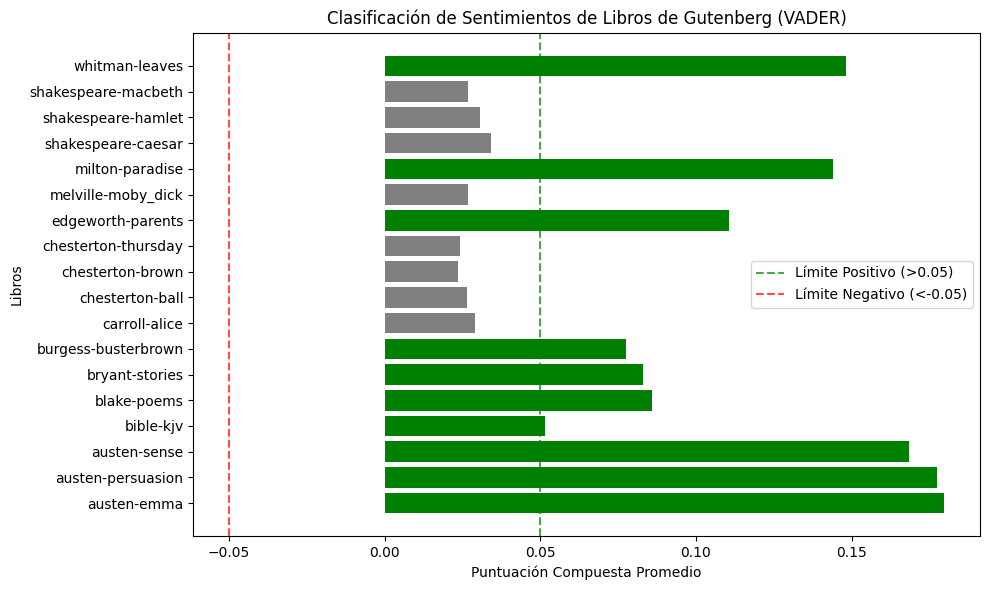

In [18]:
sia = SentimentIntensityAnalyzer()
resultados = []

for libro in gutenberg.fileids():
    # VADER tiene un límite práctico por texto largo, por lo que una opción
    # común y representativa es calcular la media de las oraciones
    oraciones = gutenberg.sents(libro)
    print(oraciones)
    # Para optimizar el rendimiento y evitar sobrecarga de memoria,
    # unimos las palabras de cada oración para pasarlas por el analizador
    scores = [sia.polarity_scores(' '.join(oracion))['compound'] for oracion in oraciones]
    score_promedio = sum(scores) / len(scores)

    # Clasificación basada en el score compuesto promedio
    if score_promedio > 0.05:
        clasificacion = 'Positivo'
    elif score_promedio < -0.05:
        clasificacion = 'Negativo'
    else:
        clasificacion = 'Neutro'

    resultados.append({
        'Libro': libro[:-4],
        'Compound_Score': score_promedio,
        'Clasificacion': clasificacion
    })

# Convertir a DataFrame para facilitar la manipulación y graficado
df = pd.DataFrame(resultados)
print(df)

# Graficar los resultados
plt.figure(figsize=(10, 6))
colores = df['Clasificacion'].map({'Positivo': 'green', 'Negativo': 'red', 'Neutro': 'gray'})
plt.barh(df['Libro'], df['Compound_Score'], color=colores)
plt.axvline(x=0.05, color='green', linestyle='--', alpha=0.7, label='Límite Positivo (>0.05)')
plt.axvline(x=-0.05, color='red', linestyle='--', alpha=0.7, label='Límite Negativo (<-0.05)')
plt.title('Clasificación de Sentimientos de Libros de Gutenberg (VADER)')
plt.xlabel('Puntuación Compuesta Promedio')
plt.ylabel('Libros')
plt.legend()
plt.tight_layout()
plt.show()

# 11. Gráfica comparativa por unica cadena

In [30]:
nltk.download('punkt', quiet=True)
nltk.download('vader_lexicon', quiet=True)

True

                  Libro  Compound_Score Clasificacion
0           austen-emma        0.172848      Positivo
1     austen-persuasion        0.174730      Positivo
2          austen-sense        0.165819      Positivo
3             bible-kjv        0.051275      Positivo
4           blake-poems        0.105945      Positivo
5        bryant-stories        0.082218      Positivo
6   burgess-busterbrown        0.076033      Positivo
7         carroll-alice        0.016560        Neutro
8       chesterton-ball        0.018004        Neutro
9      chesterton-brown        0.020572        Neutro
10  chesterton-thursday        0.021759        Neutro
11    edgeworth-parents        0.096441      Positivo
12   melville-moby_dick        0.026437        Neutro
13      milton-paradise        0.138638      Positivo
14   shakespeare-caesar        0.048430        Neutro
15   shakespeare-hamlet        0.038819        Neutro
16  shakespeare-macbeth        0.035989        Neutro
17       whitman-leaves     

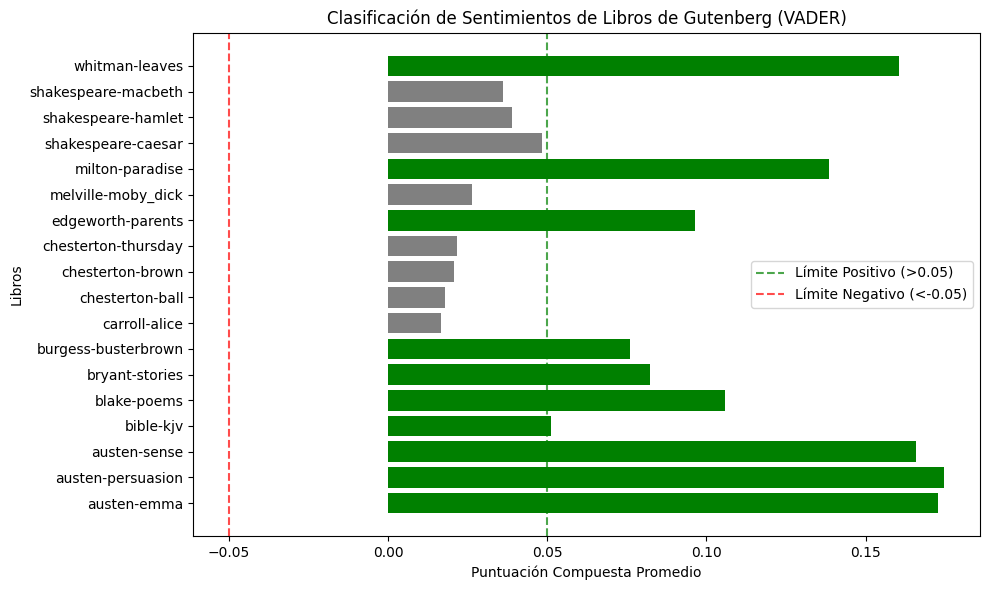

In [31]:
sia = SentimentIntensityAnalyzer()
resultados = []

for libro in gutenberg.fileids():
    texto_raw = gutenberg.raw(libro)

    oraciones = nltk.sent_tokenize(texto_raw)

    scores = [sia.polarity_scores(oracion)['compound'] for oracion in oraciones]
    
    if scores:
        score_promedio = sum(scores) / len(scores)
    else:
        score_promedio = 0.0

    # Clasificación basada en el score compuesto promedio
    if score_promedio > 0.05:
        clasificacion = 'Positivo'
    elif score_promedio < -0.05:
        clasificacion = 'Negativo'
    else:
        clasificacion = 'Neutro'

    resultados.append({
        'Libro': libro[:-4],
        'Compound_Score': score_promedio,
        'Clasificacion': clasificacion
    })

# Convertir a DataFrame para facilitar la manipulación y graficado
df = pd.DataFrame(resultados)
print(df)

# Graficar los resultados
plt.figure(figsize=(10, 6))
colores = df['Clasificacion'].map({'Positivo': 'green', 'Negativo': 'red', 'Neutro': 'gray'})
plt.barh(df['Libro'], df['Compound_Score'], color=colores)
plt.axvline(x=0.05, color='green', linestyle='--', alpha=0.7, label='Límite Positivo (>0.05)')
plt.axvline(x=-0.05, color='red', linestyle='--', alpha=0.7, label='Límite Negativo (<-0.05)')
plt.title('Clasificación de Sentimientos de Libros de Gutenberg (VADER)')
plt.xlabel('Puntuación Compuesta Promedio')
plt.ylabel('Libros')
plt.legend()
plt.tight_layout()
plt.show()

# 12. Gráfica comparativa por palabras

                  Libro  Compound_Score Clasificacion
0           austen-emma        0.177774      Positivo
1     austen-persuasion        0.164939      Positivo
2          austen-sense        0.146310      Positivo
3             bible-kjv        0.037965        Neutro
4           blake-poems        0.110915      Positivo
5        bryant-stories        0.094946      Positivo
6   burgess-busterbrown        0.095548      Positivo
7         carroll-alice        0.027371        Neutro
8       chesterton-ball        0.029405        Neutro
9      chesterton-brown        0.026043        Neutro
10  chesterton-thursday        0.028197        Neutro
11    edgeworth-parents        0.119737      Positivo
12   melville-moby_dick        0.025439        Neutro
13      milton-paradise        0.100671      Positivo
14   shakespeare-caesar        0.060987      Positivo
15   shakespeare-hamlet        0.046363        Neutro
16  shakespeare-macbeth        0.057053      Positivo
17       whitman-leaves     

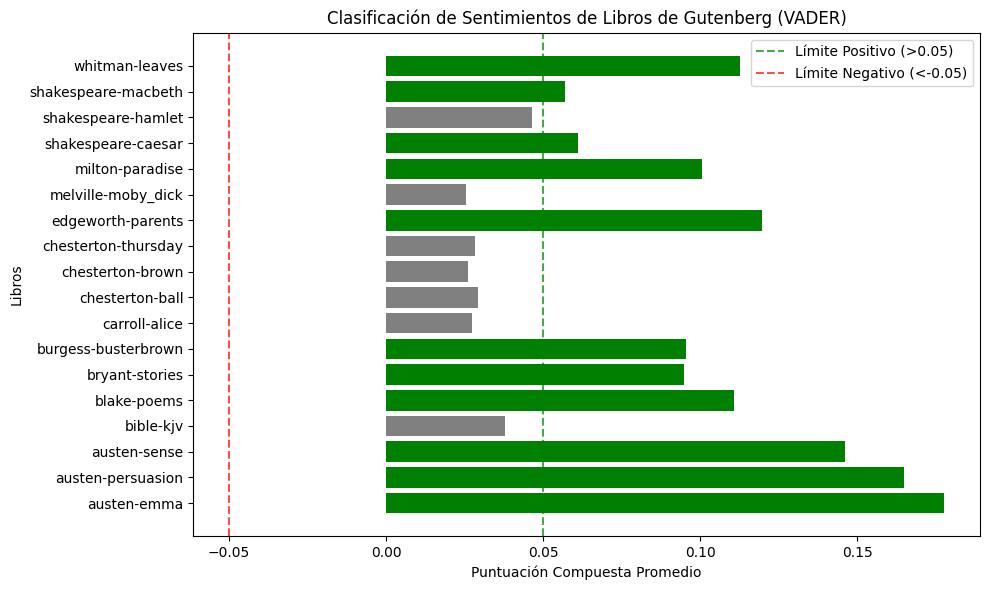

In [32]:
sia = SentimentIntensityAnalyzer()
resultados = []

for libro in gutenberg.fileids():
    palabras = gutenberg.words(libro)
    
    tamano_bloque = 20
    bloques = [' '.join(palabras[i:i + tamano_bloque]) for i in range(0, len(palabras), tamano_bloque)]
    
    scores = [sia.polarity_scores(bloque)['compound'] for bloque in bloques]
    
    if scores:
        score_promedio = sum(scores) / len(scores)
    else:
        score_promedio = 0.0

    # Clasificación basada en el score compuesto promedio
    if score_promedio > 0.05:
        clasificacion = 'Positivo'
    elif score_promedio < -0.05:
        clasificacion = 'Negativo'
    else:
        clasificacion = 'Neutro'

    resultados.append({
        'Libro': libro[:-4],
        'Compound_Score': score_promedio,
        'Clasificacion': clasificacion
    })

# Convertir a DataFrame para facilitar la manipulación y graficado
df = pd.DataFrame(resultados)
print(df)

# Graficar los resultados
plt.figure(figsize=(10, 6))
colores = df['Clasificacion'].map({'Positivo': 'green', 'Negativo': 'red', 'Neutro': 'gray'})
plt.barh(df['Libro'], df['Compound_Score'], color=colores)
plt.axvline(x=0.05, color='green', linestyle='--', alpha=0.7, label='Límite Positivo (>0.05)')
plt.axvline(x=-0.05, color='red', linestyle='--', alpha=0.7, label='Límite Negativo (<-0.05)')
plt.title('Clasificación de Sentimientos de Libros de Gutenberg (VADER)')
plt.xlabel('Puntuación Compuesta Promedio')
plt.ylabel('Libros')
plt.legend()
plt.tight_layout()
plt.show()

# 13. Gráfica comparativa por parrafos

                  Libro  Compound_Score Clasificacion
0           austen-emma        0.361950      Positivo
1     austen-persuasion        0.382977      Positivo
2          austen-sense        0.287769      Positivo
3             bible-kjv        0.061557      Positivo
4           blake-poems        0.093086      Positivo
5        bryant-stories        0.136331      Positivo
6   burgess-busterbrown        0.195626      Positivo
7         carroll-alice        0.030765        Neutro
8       chesterton-ball        0.053473      Positivo
9      chesterton-brown        0.039745        Neutro
10  chesterton-thursday        0.039150        Neutro
11    edgeworth-parents        0.222007      Positivo
12   melville-moby_dick        0.062445      Positivo
13      milton-paradise        0.190266      Positivo
14   shakespeare-caesar        0.087629      Positivo
15   shakespeare-hamlet        0.075673      Positivo
16  shakespeare-macbeth        0.060295      Positivo
17       whitman-leaves     

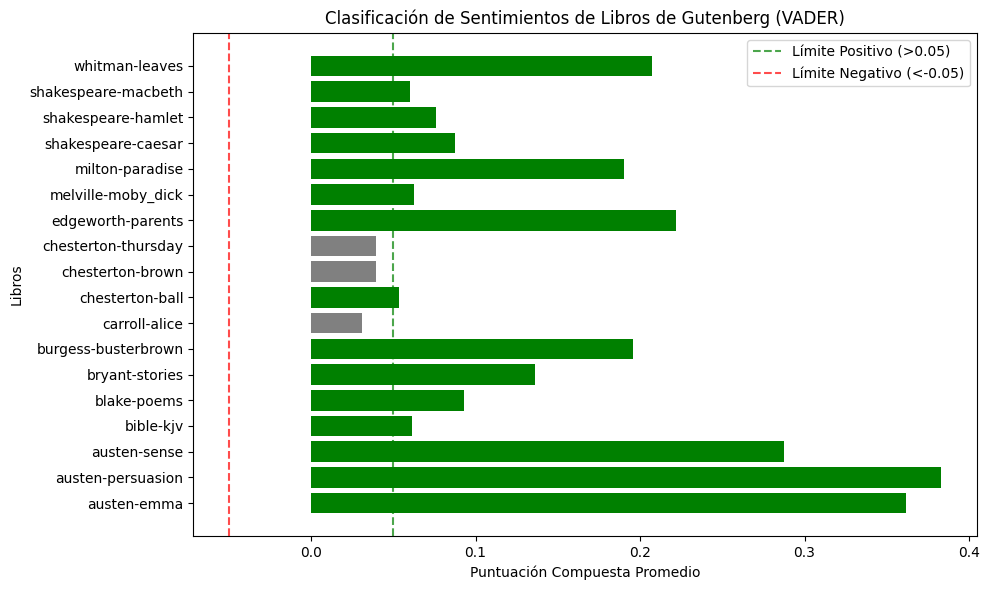

In [36]:
sia = SentimentIntensityAnalyzer()
resultados = []

for libro in gutenberg.fileids():
    parrafos = gutenberg.paras(libro)
    
    scores = []
    for parrafo in parrafos:
        texto_parrafo = ' '.join([' '.join(oracion) for oracion in parrafo])
        
        score_compuesto = sia.polarity_scores(texto_parrafo)['compound']
        scores.append(score_compuesto)
    
    if scores:
        score_promedio = sum(scores) / len(scores)
    else:
        score_promedio = 0.0
        
    # Clasificación basada en el score compuesto promedio
    if score_promedio > 0.05:
        clasificacion = 'Positivo'
    elif score_promedio < -0.05:
        clasificacion = 'Negativo'
    else:
        clasificacion = 'Neutro'

    resultados.append({
        'Libro': libro[:-4],
        'Compound_Score': score_promedio,
        'Clasificacion': clasificacion
    })

# Convertir a DataFrame para facilitar la manipulación y graficado
df = pd.DataFrame(resultados)
print(df)

# Graficar los resultados
plt.figure(figsize=(10, 6))
colores = df['Clasificacion'].map({'Positivo': 'green', 'Negativo': 'red', 'Neutro': 'gray'})
plt.barh(df['Libro'], df['Compound_Score'], color=colores)
plt.axvline(x=0.05, color='green', linestyle='--', alpha=0.7, label='Límite Positivo (>0.05)')
plt.axvline(x=-0.05, color='red', linestyle='--', alpha=0.7, label='Límite Negativo (<-0.05)')
plt.title('Clasificación de Sentimientos de Libros de Gutenberg (VADER)')
plt.xlabel('Puntuación Compuesta Promedio')
plt.ylabel('Libros')
plt.legend()
plt.tight_layout()
plt.show()

# 15. Conclusión 

RESULTADOS POR ORACIONES
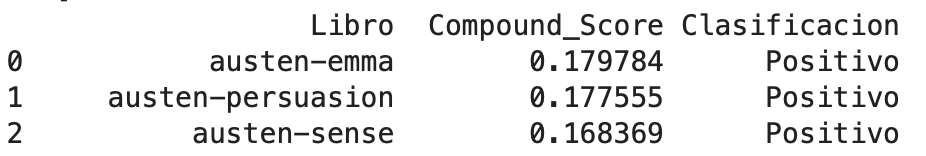
RESULTADOS POR UNICA CADENA
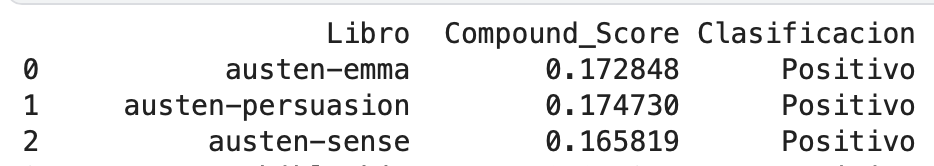
RESULTADOS POR PALABRAS
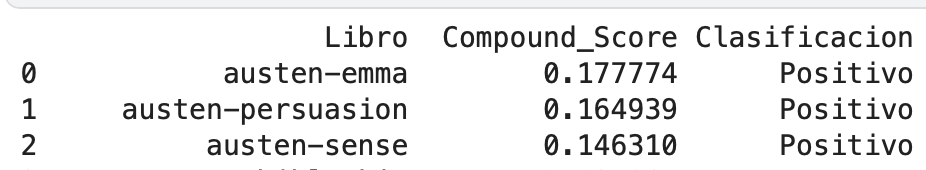
RESULTADOS POR PARRAFOS
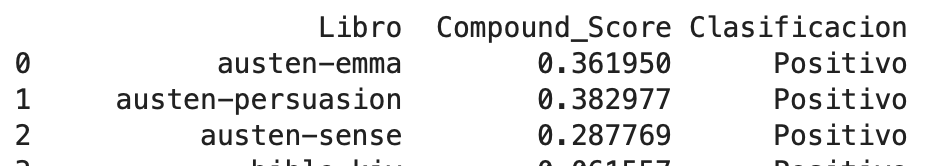

A partir de los resultados observados de los libros de Jane Austen los cuales son Emma, Persuasion y Sense. Independientemente del metodo de extraccion sease por cadena, oraciones, palabras en bloques o parrafos, los 3 libros se clasifican como positivos. 
El analisis por parrafos presenta los valores mas altos de toda la comparativa llegando hasta 0.382 en Persuasion. Esto debido a la evaluación de bloques de texto mas largos, las palabras positivas se acumulan y elevan el promedio. 
En analisis de bloques por palabras genera los puntuajes mas bajos del conjunto, destacando Sense con 0.146, esto refuerza la idea que Vader necesita mas contexto para evaluar las reglas gramaticales e intensidad de los textos. 



# 16. Modulo Corpus

El módulo `nltk.corpus` permite acceder a otras colecciones de textos en otras lenguas ([lista completa aquí](http://www.nltk.org/book/ch02.html#tab-corpora)). Vamos a probar con un corpus de noticias en castellano llamado `cess_esp` que incluye anotación morfo-sintáctica.

In [37]:
from nltk.corpus import cess_esp

# la versión en crudo de este corpus contiene información morfosintáctica con un formato que todavía no conocemos.
# en este caso, pasamos directamente a trabajar con los textos segmentados

# cargo el primer documento del corpus segmentado en palabras
palabras = cess_esp.words(cess_esp.fileids()[0])
print(palabras[:50])

print("\n", "-" * 75, "\n")

# y segmentado en oraciones
oraciones = cess_esp.sents(cess_esp.fileids()[0])
print(oraciones[:5])

['El', 'grupo', 'estatal', 'Electricité_de_France', '-Fpa-', 'EDF', '-Fpt-', 'anunció', 'hoy', ',', 'jueves', ',', 'la', 'compra', 'del', '51_por_ciento', 'de', 'la', 'empresa', 'mexicana', 'Electricidad_Águila_de_Altamira', '-Fpa-', 'EAA', '-Fpt-', ',', 'creada', 'por', 'el', 'japonés', 'Mitsubishi_Corporation', 'para', 'poner_en_marcha', 'una', 'central', 'de', 'gas', 'de', '495', 'megavatios', '.', 'Una', 'portavoz', 'de', 'EDF', 'explicó', 'a', 'EFE', 'que', 'el', 'proyecto']

 --------------------------------------------------------------------------- 

[['El', 'grupo', 'estatal', 'Electricité_de_France', '-Fpa-', 'EDF', '-Fpt-', 'anunció', 'hoy', ',', 'jueves', ',', 'la', 'compra', 'del', '51_por_ciento', 'de', 'la', 'empresa', 'mexicana', 'Electricidad_Águila_de_Altamira', '-Fpa-', 'EAA', '-Fpt-', ',', 'creada', 'por', 'el', 'japonés', 'Mitsubishi_Corporation', 'para', 'poner_en_marcha', 'una', 'central', 'de', 'gas', 'de', '495', 'megavatios', '.'], ['Una', 'portavoz', 'de', 'E

In [ ]:
print(" ".join(palabras[:100]))

De manera similar a como hemos hecho sacando estadísticas de las obras disponibles en el corpus `gutenberg`, vamos a calcular la longitud promedio de palabras y el número de palabras promedio por oración, para los diez primeros documentos de este corpus `cess_esp`.

Fíjate en la estructura de este ejemplo: contiene bucles anidados.

In [38]:
# para cada documento que está entre los 10 primeros del corpus
for documento in cess_esp.fileids()[:10]:
    # carga el texto segmentado en palabras
    palabras = cess_esp.words(documento)
    # y en oraciones
    oraciones = cess_esp.sents(documento)

    # pon el contador de caracteres a 0
    caracteres = 0
    # para cada palabra dentro de la lista de palabras del documento
    for palabra in palabras:
        # ve sumando al contador el número de caracteres que tiene la palabra en cuestión
        caracteres = caracteres + len(palabra)

    # cuando hayas terminado, divide la longitud total del texto entre el número de palabras
    longitud_promedio = caracteres / len(palabras)

    # imprime el nombre del documento, la longitud de la palabra y el número de palabras por oración
    print(
        documento[:-4],
        "\t",
        round(longitud_promedio, 2),
        "\t",
        round(len(palabras) / len(oraciones), 2),
    )

10017_20000413 	 5.04 	 42.17
10044_20000313 	 4.27 	 47.62
10049_20001114 	 5.84 	 31.11
10055_20000713 	 4.98 	 30.89
10080_20000914 	 4.6 	 34.0
10084_20000313_1 	 4.54 	 42.36
10084_20000313_2 	 4.71 	 24.0
10127_20001013_1 	 4.63 	 40.1
10127_20001013_2 	 4.71 	 32.1
10127_20001013_3 	 4.72 	 35.29


Los libros del Proyecto Gutenberg constituyen el tipo de corpus más sencillo: no está anotado (no incluye ningún tipo de información lingüística) ni categorizado.

## Corpus categorizados y anotados: el Corpus de Brown

El Corpus de Brown fue el primer gran corpus orientado a tareas de PLN. Desarrollado en la Universidad de Brown, contiene más de un millón de palabras provenientes de 500 fuentes.  La principal catacterística de este corpus es que sus textos están categorizados por género.

In [ ]:
from nltk.corpus import brown

Como en los libros del Proyecto Gutenberg, aquí también podemos imprimir los nombres de los ficheros. En este caso son poco significativos, nos nos dicen nada del contenido.

In [ ]:
# Brown está formado por 500 documentos
print(len(brown.fileids()))
# imprimimos solos los 10 primeros
print(brown.fileids()[:10])

### El corpus de Brown está categorizado por géneros

Una de las principales diferencias con otros corpus vistos anteriormente es que el de Brown está categorizado: los textos están agrupados según su género o temática. Y en este caso, los nombres de las categorías sí nos permiten intuir el contenido de los textos.

In [ ]:
print(brown.categories())

De manera similar a los libros del Proyecto Gutenberg, podemos acceder a los textos de este corpus a través de los métodos `brown.raw`, `brown.words`, `brown.sents` y `brown.paras`. Además, podemos acceder a una categoría de textos concretas si lo especificamos como argumento.

In [ ]:
news_words = brown.words(categories="news")
scifi_sents = brown.sents(categories="science_fiction")

In [ ]:
print(news_words[:50])
print("\n", "-" * 75, "\n")
print(scifi_sents[:3])

Vamos a sacar provecho de la categorización de los textos de este corpus. Para ello, vamos a calcular la frecuencia de distribución de distintos verbos modales para cada categoría. Para ello vamos a calcular una distribución de frecuencia condicional que calcule la frecuencia de cada palabra para cada categoría.

No te preocupes si no entiendes la sintaxis para crear tablas de frecuencias condicionales a través del objeto `ConditionalFreqDist`. Créeme, ese objeto calcula frecuencias de palabras atendiendo a la categoría en la que aparecen y crea una especie de diccionario de diccionarios.

In [ ]:
from nltk import ConditionalFreqDist

modals = "can could would should must may might".split()
modals_cfd = ConditionalFreqDist(
    (category, word)
    for category in brown.categories()
    for word in brown.words(categories=category)
)

# la sintaxis anterior contiene varios bucles anidados y es equivalente a:
# for category in brown.categories():
#     for word in brown.words(categories=category):
#         ConditionalFreqDist(category, word)

Una vez tenemos calculada la frecuencia de distribución condicional, podemos pintar los valores fácilmente en forma de tabla a través del método `.tabulate`, especificando como condiciones cada una de las categorías, y como muestras los verbos modales del inglés que hemos definido.

In [ ]:
modals_cfd.tabulate(conditions=brown.categories(), samples=modals)

Las cifras que hemos mostrado en las tablas anteriores se refieren a las frecuencias absolutas de cada verbo modal en cada categoría. Realizar comparaciones así no es acertado, porque es posible que cada categoría tenga un número de documentos (y de palabras) diferente.

Vamos a comprobar si esto es cierto. ¿Está equilibrada la colección o tenemos algunos géneros sobrerrepresentados?

In [ ]:
for categoria in brown.categories():
    print(categoria, len(brown.words(categories=categoria)))

Como vemos, el número de palabras no está equilibado. Tenemos muchos más datos en las categorías `belles_lettres` y `learned` que en `science_fiction` o `humor`, por ejemplo.

Calculemos a continuación la frecuencia relativa de estos verbos modales, atendiendo al género. Para ello, necesitamos dividir la frecuencia absoluta de cada modal entre el número de palabras total de cada categoría.

In [ ]:
for categoria in brown.categories():
    # ¿cuántas palabras tenemos en cada categoría?
    longitud = len(brown.words(categories=categoria))
    print("\n", categoria)
    print("\n", "-" * 75, "\n")
    for palabra in modals:
        print(palabra, "->", modals_cfd[categoria][palabra] / longitud)

Vamos a repetir la operación de cálculo de frecuencias relativas reasignando estos valores en el propio objeto `modals_cfd`, con el objetivo de utilizar el método `tabulate` para poder impirmir la tabla con los valors relativos.

In [ ]:
# lo primero, realizo una copia de mi distribución de frecuencias
import copy

modals_cfd_rel = copy.deepcopy(modals_cfd)

In [ ]:
# sustituyo los conteos de la tabla por sus frecuencias relativas (ojo, en tantos por 10.000)
for categoria in brown.categories():
    longitud = len(brown.words(categories=categoria))
    for palabra in modals:
        modals_cfd_rel[categoria][palabra] = (
            modals_cfd[categoria][palabra] / longitud
        ) * 10000

In [ ]:
# imprimo la tabla
modals_cfd_rel.tabulate(conditions=brown.categories(), samples=modals)

### Brown es también un corpus anotado con información morfológica

El corpus de Brown no solo está categorizado, también está anotado con información morfológica. Para acceder a la versión anotada del corpus, podemos utilizar los métodos: `brown.tagged_words`, `brown.tagged_sents` y `brown.tagged_
paras`

In [ ]:
scifi_tagged_words = brown.tagged_words(categories="science_fiction")
print(scifi_tagged_words[:50])

Fíjate que cuando accedemos a la versión etiquetada del corpus, no obtenemos una simple lista de palabras sino una lista de tuplas, donde el primer elemento es la palabra en cuestión u el segundo es la etiqueta que indica la categoría gramatical de la palabra.

Este conjunto etiquetas se ha convertido en casi un estándar para el inglés y se utilizan habitualmente para anotar cualquier recurso lingüístico en esa lengua.

Vamos a crear una nueva frecuencia de distribución condicional para calcular la frecuencia de aparición de las etiquetas, teniendo en cuenta la categoría.

In [ ]:
tags_cfd = ConditionalFreqDist(
    (category, item[1])
    for category in brown.categories()
    for item in brown.tagged_words(categories=category)
)

Y ahora vamos a imprimir la tabla de frecuencias para cada categoría y para algunas de las etiquetas morfológicas: sustantivos en singular `NN`, verbos en presente `VB`, verbos en pasado simple `VBD`, participios pasados `VBN`, adjetivos `JJ`, preposiciones `IN`, y artículos `AT`.

Recuerda: estas cifras no son directamente comparables entre categorías ya que éstas no están equilibradas. Hay categorías con más textos que otras.

In [ ]:
tags_cfd.tabulate(
    conditions=brown.categories(), samples="NN VB VBD VBN JJ IN AT".split()
)

### Ejercicio 1: buscando adjetivos

Creamos una lista de adjetivos (etiquetados como JJ) que aparezcan en la colección de textos categorizados como *hobbies*, e imprimimos por pantalla los 50 primeros que encontramos.

In [ ]:
# escribe tu código aquí

### Ejercicio 2: buscando palabras largas

Recorre cada categoría del corpus de Brown buscando adjetivos, e imprime solo aquellos que tengan una longitud de al menos 15 caracteres y que no sean palabras compuestas escritas con guiones ortográficos.

In [ ]:
# escribe tu código aquí

### Ejercicio 3: Frecuencias de palabras en castellano

Procesa una novela en castellano (p. ej. *Fortunata y Jacinta*), tokenizando y normalizando el texto, para calcular una distribución de frecuencias de las palabras.

In [ ]:
# escribe tu código aquí

### Ejercicio 4: Frecuencias de palabras en inglés

Repite el proceso con un texto en inglés (p. ej. *Sherlock Holmes*).

In [ ]:
# escribe tu código aquí

## Recursos Léxicos: WordNet

[Wordnet](https://wordnet.princeton.edu) es una red semántica para el inglés. En esencia, es similar a un diccionario pero está organizado por *synsets* (conjunto de palabras sinónimas) y no por lemas.

Podemos acceder a WordNet a través de NLTK, de manera similar a como accedemos desde el [interfaz web](http://wordnetweb.princeton.edu/perl/webwn):


In [ ]:
from nltk.corpus import wordnet as wn

Para consultar los synsets en los que aparece una determinada palabra, podemos utilizar el método `.synsets` como se muestra en el ejemplo. Como resultado obtenemos una lista con todos los synsets en los que aparece la palabra.

In [ ]:
# buscamos los synsets en los que aparece la palabra sword
print(wn.synsets("sword"))

# y buscamos car
print(wn.synsets("car"))

En este caso, la palabra *sword* solo aparece en un synset, lo que implica que solo tiene un sentido. Además, sabemos que es un sustantivo, porque el nombre de synset está etiquetado como `n`.

Por su parte, la palabra *car* es polisémica y aparece en cinco sentidos, toso ellos sustantivos.

Si guardo el synset en cuestión en una variable (fíjate que me quedo con el primer elemento de la lista que me devuelve el método `wn.synsets`), podemos acceder a distintos métodos:

In [ ]:
sword = wn.synsets("sword")[0]
print(sword.lemma_names())  # imprime los lemas del synset => sinónimos
print(sword.definition())  # imprime la definición del synset

# hacemos lo mismo con car
car = wn.synsets("car")
cable_car = car[-1]
print(cable_car.lemma_names(), cable_car.definition())
print(
    car[-1].lemma_names(), car[-1].definition()
)  # esta línea es equivalente a la anterior. ¿Ves por qué?

# imprimo las oraciones de ejemplo
print(cable_car.examples())

In [ ]:
sword.

Si escribes `sword.` y pulsas el tabulador podrás visualizar todos los métodos accesibles desde un objeto synset. Son muchos: si tienes interés en alguno que no se menciona en este resumen, pregúntame o consulta el libro de NLTK.

Entre las cosas que sí nos interesan está el poder acceder a relaciones como hiponimia, meronimia, etc. Por ejemplo, para acceder a todos los hipónimos de *sword* con el sentido de *espada*, es decir, a todos los **tipos de** *espada* y a sus definiciones.

In [ ]:
print(sword.hyponyms())

for element in sword.hyponyms():
    print(element.lemma_names())
    print(element.definition())

En lugar de bajar hasta los elementos más específicos, podemos navegar en la jerarquía de sentidos hasta los synsets más generales. Por ejemplo, podemos acceder a los hiperónimos inmediatos de un synset a través del método `.hypernyms()`:

In [ ]:
for element in sword.hypernyms():
    print(element.lemma_names())
    print(element.definition())

Fíjate que con este método sólo subimos un nivel hacia el synset más general. En este caso, comprobamos que *sword* es un tipo de *weapon* o *arm*. Si, por el contrario, lo que nos interesa es acceder a todos los hiperónimos de *sword*, navegando hasta el elemento raíz de la jerarquía de WordNet (que siempre es *entity*), podemos utilizar el método `.hypernym_paths()`:

In [ ]:
for path in sword.hypernym_paths():
    for element in path:
        print(element.lemma_names())
        print(element.definition())

Fíjate que `.hypernym_paths()` me devuelve una lista de caminos posibles desde el synset en cuestión hasta el elemento *entity*. Por eso itero sobre los elementos `path` que me devuelve `.hypernym_paths()`. En el ejemplo de *sword*, da la casualidad de que solo hay un camino posible. Cada `path` es una lista de synsets, e itero sobre ellos. Por eso utilizo un bucle dentro de otro.

Para acceder a los merónimos, es decir, a las partes o elementos constitutivos de *sword*, podemos utilizar el método `.part_meronyms()`, como se muestra a continuación.

In [ ]:
for element in sword.part_meronyms():
    print(element.lemma_names())
    print(element.definition())

De manera similar, podemos acceder a los holónimos de un synset, es decir, a los elementos de los que *espada* forma parte, a través del método `.part_holonyms()`. El synset que estamos utilizando no tiene definidos holónimos, así que el ejemplo devuelve una lista vacía.

In [ ]:
print(sword.part_holonyms())

Busquemos ahora algún ejemplo que tenga otros tipos de merónimos.

In [ ]:
# en cuántos synsets aparece la palabra water?
water = wn.synsets("water")
for synset in water:
    print(synset.lemma_names())

# me quedo con el primero
agua = water[0]
# que tiene unos cuantos merónimos de sustancia
print(agua.substance_meronyms())

# ídem para air
air = wn.synsets("air")
for synset in air:
    print(synset.lemma_names(), synset.definition())

aire = air[0]
print(aire.substance_meronyms())

Hay varios métodos para acceder a distintos tipos de merónimos y holónimos, aunque no siempre están definidas estas relaciones. Cuando no están definidas, los métodos no dan error, simplemente devuelven listas vacías.

Los nombres de estos métodos tratan de ser autoexplicativos: por un lado, tenemos `.part_holonyms()`, `.member_holonyms()`, `.substance_holonyms()`, y por otro, `.part_meronyms()`, `.member_meronyms()`, `.substance_meronyms()`.

### Ejercicio 5

- Busca los sentidos en los que aparece la palabra *bike*.
- Identifica el que hace referencia a *bicicleta* como *vehículo de dos ruedas a pedales*
- Imprime los merónimos, esto es, las partes que conforman una bicicleta

In [ ]:
# escribe tu código aquí